# Load packages

In [4]:
import json
from collections import namedtuple, Counter

import numpy as np
import scanpy as sc
import pandas as pd
import squidpy as sq

## Image manipulation and geometry
from tifffile import imread
from skimage.io import imread as skimread


## Plotting imports
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_hex, Colormap
from matplotlib.cm import ScalarMappable
from matplotlib.colorbar import ColorbarBase
from matplotlib.lines import Line2D
from matplotlib import rc_context

## Load data

In [ ]:
adata = sc.read_h5ad("/path/to/Resolve_adult_ovary_atresia_update.h5ad")
adata

AnnData object with n_obs × n_vars = 251419 × 80
    obs: 'resolve_cell_id', 'roi_id', 'tissue_section', 'donor_id', 'x_px', 'y_px', 'x_um', 'y_um', 'leiden_cluster', 'cell_type', 'cell_type_full', 'cell_type_broad', 'follicle_category', 'follicle_id', 'follicle_diameter_mm', 'total_counts', 'norm_total_counts', 'n_genes_detected', 'follicle_id_original', 'follicle_diameter_mm_original'
    var: 'n_cells_detected', 'total_counts'
    uns: 'cell_type_colors', 'leiden_cluster_colors'
    obsm: 'X_umap', 'spatial', 'spatial_px'
    layers: 'counts', None (.X)

In [13]:
adata.obs

,resolve_cell_id,roi_id,tissue_section,donor_id,x_px,y_px,x_um,y_um,leiden_cluster,cell_type,cell_type_full,cell_type_broad,follicle_category,follicle_id,follicle_diameter_mm,total_counts,norm_total_counts,n_genes_detected,follicle_id_original,follicle_diameter_mm_original
cell_id,,,,,,,,,,,,,,,,,,,,
A1_3__Cell1_2180_16,Cell1_2180_16,A1_3,A1,FTM120,2180.0,16.0,300.689655,2.206897,1,atr.ST,Atretic stroma,ex.TC/ST,atretic_type3,type3_1,0.7,23,23,11,type3_1,0.7
A1_3__Cell2_2297_13,Cell2_2297_13,A1_3,A1,FTM120,2297.0,13.0,316.827586,1.793103,1,atr.ST,Atretic stroma,ex.TC/ST,atretic_type3,type3_1,0.7,30,30,17,type3_1,0.7
A1_3__Cell3_2340_2,Cell3_2340_2,A1_3,A1,FTM120,2340.0,2.0,322.758621,0.275862,1,atr.ST,Atretic stroma,ex.TC/ST,atretic_type3,type3_1,0.7,3,3,2,type3_1,0.7
A1_3__Cell4_2433_8,Cell4_2433_8,A1_3,A1,FTM120,2433.0,8.0,335.586207,1.103448,1,atr.ST,Atretic stroma,ex.TC/ST,atretic_type3,type3_1,0.7,29,29,12,type3_1,0.7
A1_3__Cell5_2543_3,Cell5_2543_3,A1_3,A1,FTM120,2543.0,3.0,350.758621,0.413793,1,atr.ST,Atretic stroma,ex.TC/ST,atretic_type3,type3_1,0.7,10,10,4,type3_1,0.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
D2_1__Cell9330_7186_10693,Cell9330_7186_10693,D2_1,D2,FTM44,7186.0,10693.0,991.172414,1474.896552,3,in.TC,Internal theca cells,in.TC,healthy,healthy_6,1.9,137,137,15,healthy_6,1.9
D2_1__Cell9331_9416_10684,Cell9331_9416_10684,D2_1,D2,FTM44,9416.0,10684.0,1298.758621,1473.655172,2,ex.TC,External theca cells,ex.TC/ST,healthy,healthy_6,1.9,349,349,41,healthy_6,1.9
D2_1__Cell9332_2161_10668,Cell9332_2161_10668,D2_1,D2,FTM44,2161.0,10668.0,298.068966,1471.448276,2,ex.TC,External theca cells,ex.TC/ST,healthy,healthy_6,1.9,235,235,28,healthy_6,1.9


We prefer to use our own color palette, define it here

In [14]:
#set color
custom_palette = {
    "0": "#515151",
    "1": "#AB76AE",
    "2": "#ffa5aa",
    "3": "#FE664D",
    "4": "#ff002a",
    "5": "#00FFFF",
    "6": "#32a852",
    "7": "#e5e022",
    "8": "#565DFD",
    "9": "#4fa9ff",
    "10": "#F032E6",
    "11": "#32a88e",
    "12": "#FF1493",
    "13": "#FF1493",
    "14": "#9f50f9",
    "15": "#AB76AE",
    "16": "#999999",
    "17": "#515151",
    "18": "#FFD700",
    "19": "#00FFFF",
    "20": "#3694a8",
    "21": "#FF6347",
    "22": "#ffa5aa",
    "23": "#32a852",
    "24": "#a8329e",
    "25": "#3255a8",
    "26": "#a88232",
    "27": "#32a88e",
    "28": "#a83250",
}

Plot UMAP with clusters

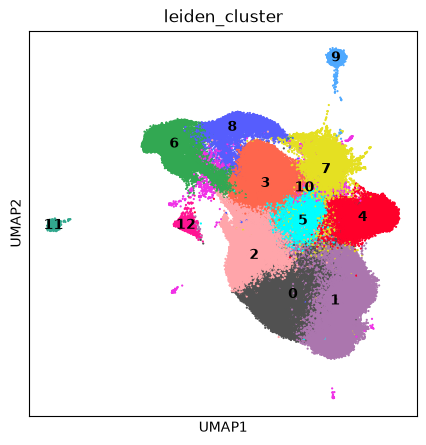

In [15]:
with rc_context({'figure.figsize': (5, 5)}):
     sc.pl.umap(adata,color=[ "leiden_cluster",], size=10,palette=custom_palette,legend_loc="on data")

Plot cell attributes, per ROI, on spatial coordinates. We use squidpy plotting function. Each cell is a point

/home/imoustakas/miniconda3/envs/squidpy/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/imoustakas/miniconda3/envs/squidpy/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


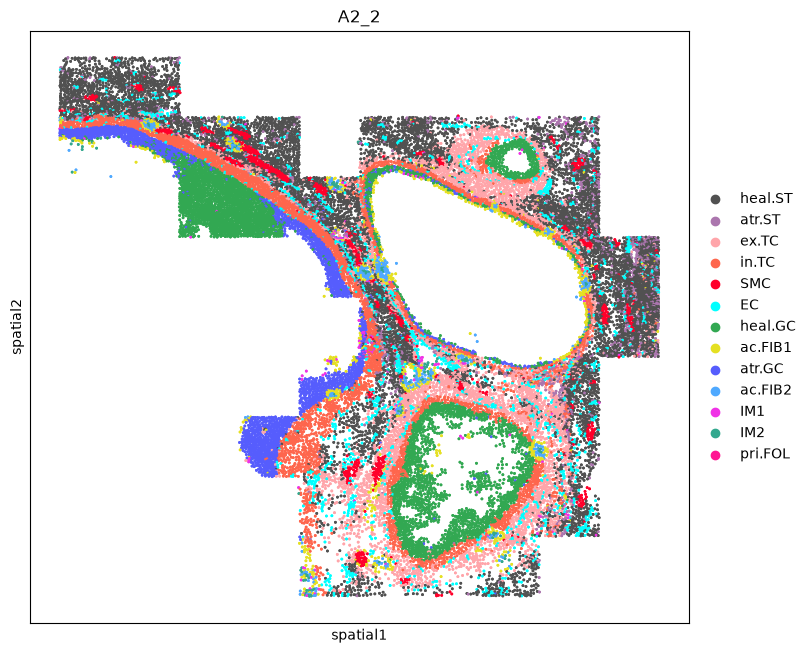

In [23]:
roi = "A2_2"

adata_roi = adata[
    adata.obs["roi_id"] == roi
].copy()


sq.pl.spatial_scatter(
    adata_roi,
    color="cell_type",
    shape=None,
    size=4,
    figsize=(8, 8),
    title=roi
)

plt.show()

/home/imoustakas/miniconda3/envs/squidpy/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/imoustakas/miniconda3/envs/squidpy/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


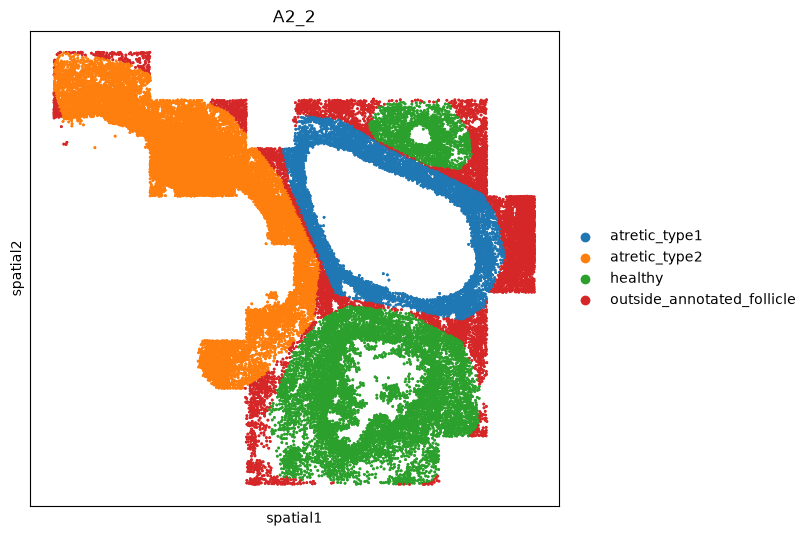

In [ ]:
roi = "A2_2"

adata_roi = adata[
    adata.obs["roi_id"] == roi
].copy()


sq.pl.spatial_scatter(
    adata_roi,
    color="follicle_category",
    shape=None,
    size=4,
    figsize=(8, 8),
    title=roi
)

plt.show()

## Plot cells as polygons
On spatial coordinates, plot cells as polygons. Get the polygon info from polygon file 

Polygon coordinate rows: 3469675
Unique segmented cells: 26306
Cells in adata for ROI A2_2: 26306
Number of common cell IDs between polygons and AnnData: 26306
Number of valid polygons for plotting: 25514


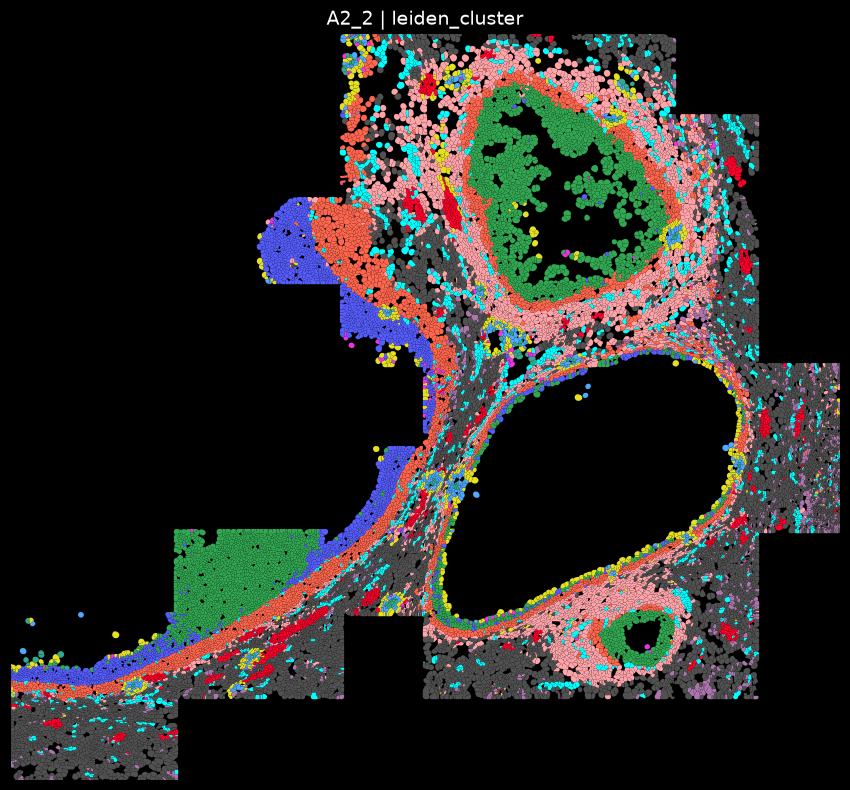

In [ ]:
# For a single sample / ROI

import geopandas as gpd

from shapely.geometry import Polygon
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

# ============================================================
# 1. Define ROI information
# ============================================================

# ROI name used in adata.obs["roi_id"]
roi_id = "A2_2"

# Identifier used in the polygon file name
# Change this if your file name uses a different style
identifier = "A2-2"

# Figure size
Width_kpx = 8.6
Height_kpx = 8.6

# ============================================================
# 2. Read polygon coordinates
# ============================================================

polygon_file = f"/exports/sasc/project-474-spatial_transcriptomics_sylwia/data/Raw_data_segmented/Segmentation/33422-2363-adult1_{identifier}_DAPI__7.5_mu_dilated_segmentation_cell_polygons.csv"

df = pd.read_csv(
    polygon_file,
    header=None,
    names=["cell_id", "x", "y"]
)

print(f"Polygon coordinate rows: {len(df)}")
print(f"Unique segmented cells: {df['cell_id'].nunique()}")

# ============================================================
# 3. Build polygons grouped by cell_id
# ============================================================

geometries = []
cell_ids = []

for cell_id, group in df.groupby("cell_id"):
    coords = list(zip(group["x"], group["y"]))

    # Need at least 3 points to define a polygon
    if len(coords) >= 3:
        polygon = Polygon(coords)
        geometries.append(polygon)
        cell_ids.append(str(cell_id))

xenium_cell_polygons = gpd.GeoDataFrame(
    {
        "cell_id": cell_ids,
        "geometry": geometries
    }
)

# ============================================================
# 4. Subset AnnData to the selected ROI
# ============================================================

adata_roi = adata[
    adata.obs["roi_id"].astype(str) == roi_id
].copy()

print(f"Cells in adata for ROI {roi_id}: {adata_roi.n_obs}")

# ============================================================
# 5. Match cell IDs between polygon file and AnnData
# ============================================================

# Polygon file contains Resolve cell IDs such as "Cell1_..."
xenium_cell_ids = set(
    xenium_cell_polygons["cell_id"].astype(str)
)

# In your AnnData, the matching ID is stored in "resolve_cell_id"
adata_cell_ids = set(
    adata_roi.obs["resolve_cell_id"].astype(str)
)

# Find common cell IDs
common_cell_ids = xenium_cell_ids & adata_cell_ids

print(
    f"Number of common cell IDs between polygons and AnnData: {len(common_cell_ids)}"
)

# ============================================================
# 6. Create a mapping from resolve_cell_id to Leiden cluster
# ============================================================

cluster_map = dict(
    zip(
        adata_roi.obs["resolve_cell_id"].astype(str),
        adata_roi.obs["leiden_cluster"].astype(str)
    )
)

# ============================================================
# 7. Collect valid polygons and their cluster labels
# ============================================================

valid_polygons = []
valid_clusters = []

for _, row in xenium_cell_polygons.iterrows():
    cell_id = str(row["cell_id"])
    geom = row.geometry

    # Only keep shared cell IDs and valid polygon geometries
    if (
        cell_id in common_cell_ids
        and geom.is_valid
        and geom.geom_type == "Polygon"
        and len(geom.exterior.coords) >= 3
    ):
        coords = list(geom.exterior.coords)
        valid_polygons.append(coords)
        valid_clusters.append(cluster_map[cell_id])

print(f"Number of valid polygons for plotting: {len(valid_polygons)}")

if len(valid_polygons) == 0:
    raise ValueError("No valid polygons were found for plotting.")

# ============================================================
# 8. Plot polygons using the custom Leiden palette
# ============================================================

fig, ax = plt.subplots(figsize=(Width_kpx, Height_kpx))

fig.patch.set_facecolor("black")
ax.set_facecolor("black")

patches = []
facecolors = []

for polygon_coords, cluster_value in zip(valid_polygons, valid_clusters):
    patch = MplPolygon(
        polygon_coords,
        closed=True
    )
    patches.append(patch)

    facecolors.append(
        custom_palette.get(str(cluster_value), "#BDBDBD")
    )

collection = PatchCollection(
    patches,
    facecolor=facecolors,
    edgecolor="none",
    linewidth=0
)

ax.add_collection(collection)

# ============================================================
# 9. Set plot limits automatically
# ==============================geometries==============================

all_x = [
    coord[0]
    for polygon in valid_polygons
    for coord in polygon
]

all_y = [
    coord[1]
    for polygon in valid_polygons
    for coord in polygon
]

ax.set_xlim(min(all_x), max(all_x))
ax.set_ylim(min(all_y), max(all_y))

# Keep the geometry undistorted
ax.set_aspect("equal")

# Uncomment this line if you want to flip the y-axis
# ax.invert_yaxis()

# Remove axes
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

ax.set_title(
    f"{roi_id} | leiden_cluster",
    color="white",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Plot gene expression 
On spatial coordinates, cells as points, per ROI

/home/imoustakas/miniconda3/envs/squidpy/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/imoustakas/miniconda3/envs/squidpy/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/imoustakas/miniconda3/envs/squidpy/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A

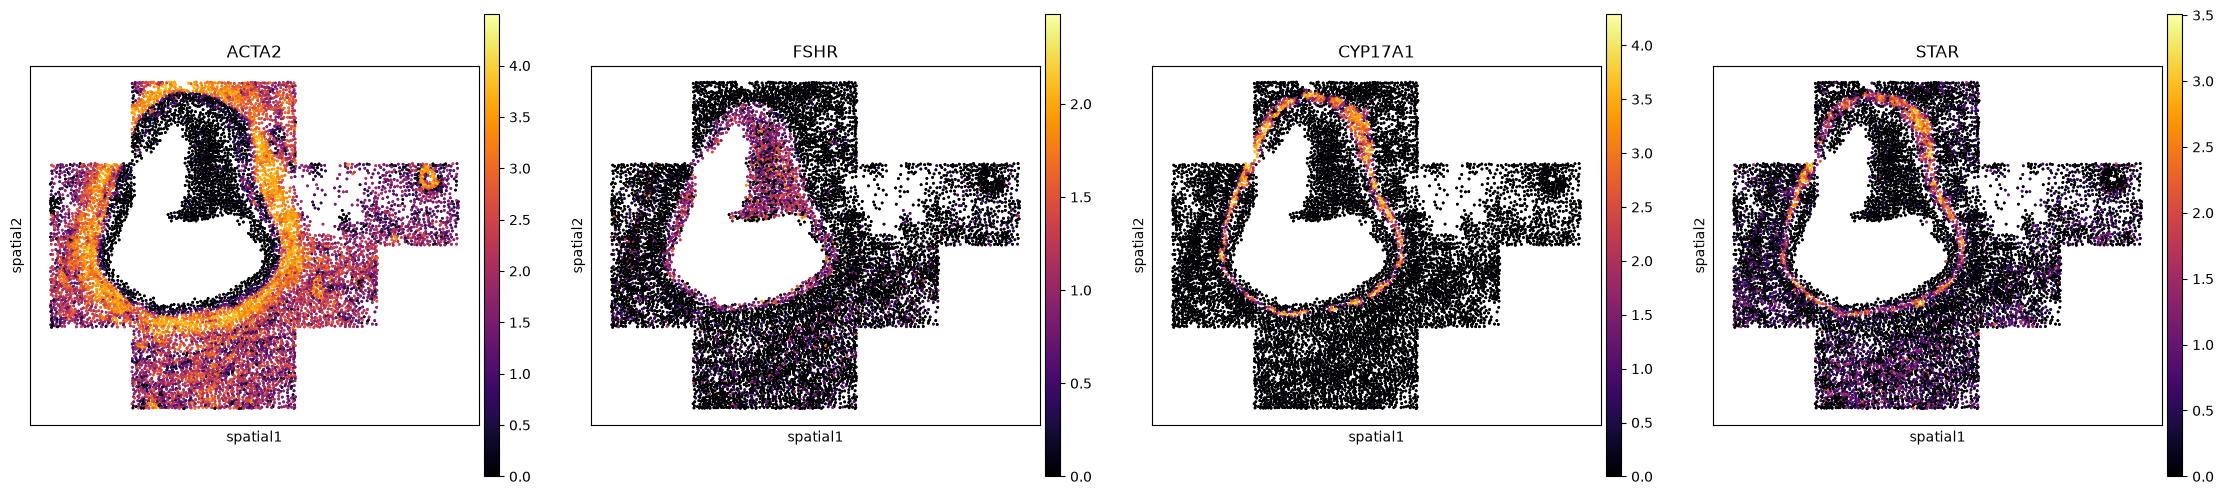

In [28]:
roi = "C1_1"

adata_roi = adata[
    adata.obs["roi_id"] == roi
].copy()

genes = [
    "ACTA2",
    "FSHR",
    "CYP17A1",
    "STAR"
]

sq.pl.spatial_scatter(
    adata_roi,
    color=genes,
    shape=None,
    size=4,
    cmap="inferno",
    figsize=(6, 6)
)

plt.show()

## Plot cells as polygons, visualize gene expression
On spatial coordinates, plot cells as polygons. Get the polygon info from polygon file 

Missing genes (0):
[]

Genes to plot (2):
['ACTA2', 'FSHR']

ROI: C1_1
Cells in polygon file: 9444
Matched cells: 9444


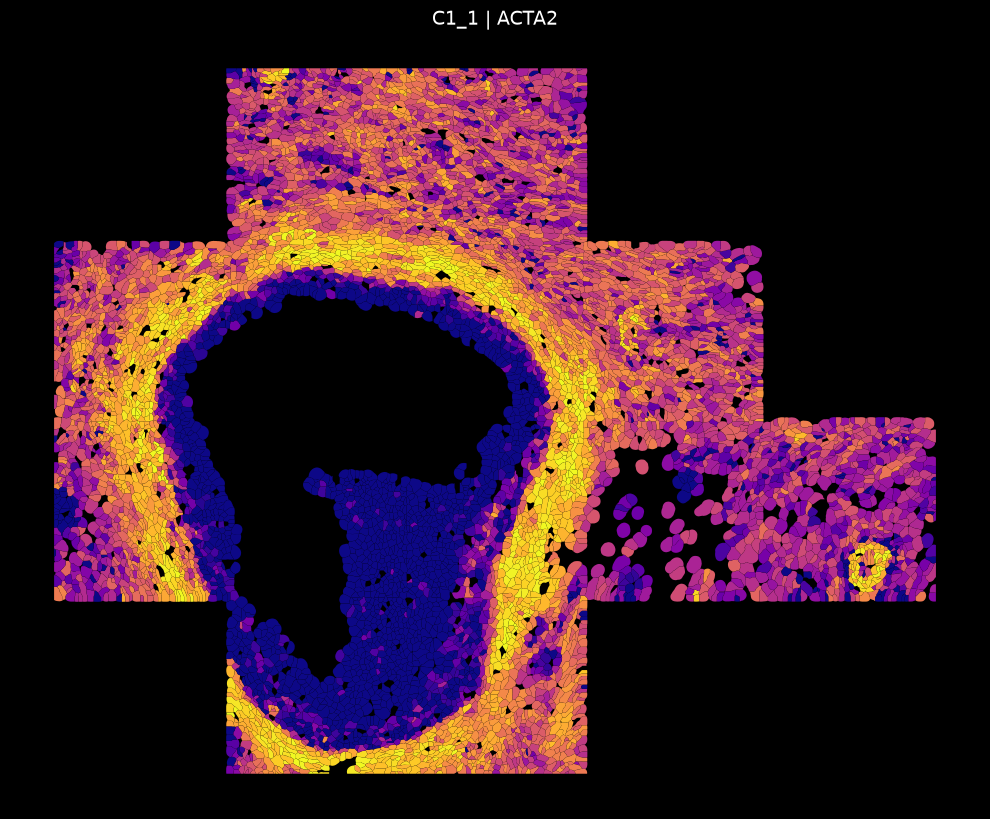

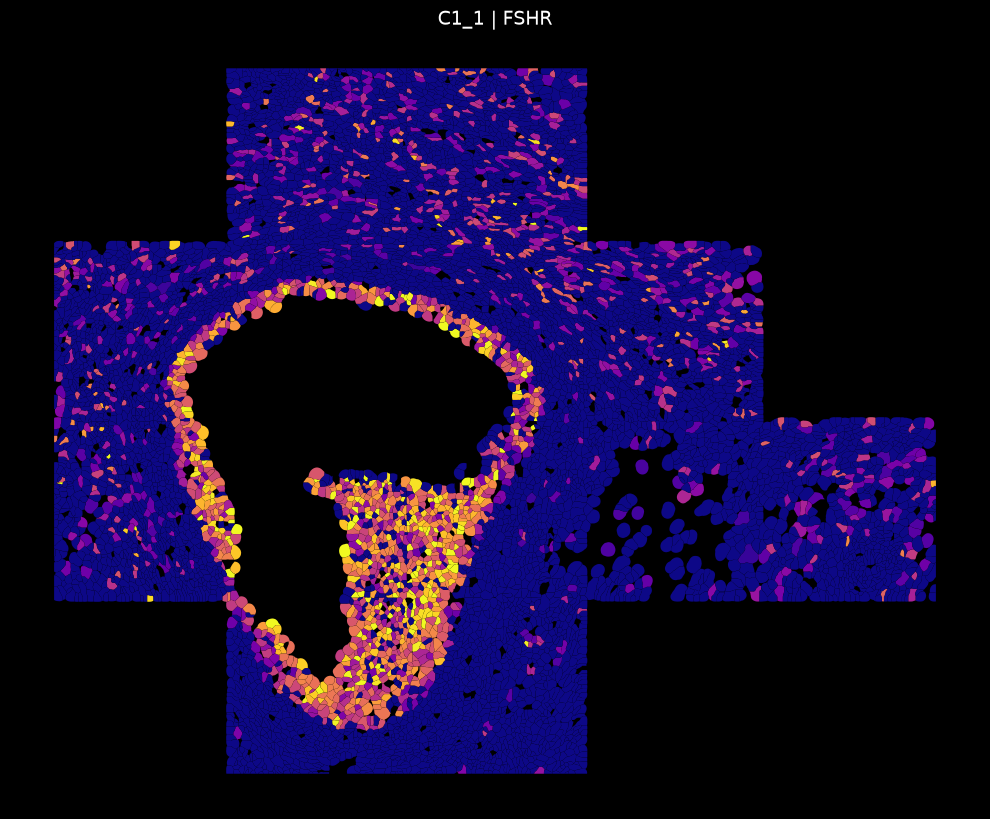

In [30]:
from matplotlib.colors import Normalize
from shapely.geometry import Polygon
from scipy.sparse import issparse


# ============================================================
# Configuration
# ============================================================

ROI_ID = "C1_1"
IDENTIFIER = "C1-1"

TARGET_GENES = [
   "ACTA2",
    "FSHR",
]

SAMPLE_CSV_PATH = f"/exports/sasc/project-474-spatial_transcriptomics_sylwia/data/Raw_data_segmented/Segmentation/33422-2363-adult1_{IDENTIFIER}_DAPI__7.5_mu_dilated_segmentation_cell_polygons.csv"


FIGSIZE = (10, 10)
CMAP = "plasma"


# ============================================================
# Check gene availability
# ============================================================

missing_genes = [
    gene for gene in TARGET_GENES
    if gene not in adata.var_names
]

existing_genes = [
    gene for gene in TARGET_GENES
    if gene in adata.var_names
]

print(f"Missing genes ({len(missing_genes)}):")
print(missing_genes)

print(f"\nGenes to plot ({len(existing_genes)}):")
print(existing_genes)


# ============================================================
# Plot gene expression
# ============================================================

def plot_genes(adata, csv_path, genes, roi_id):

    # --------------------------------------------------------
    # Read polygon coordinates
    # --------------------------------------------------------

    df = pd.read_csv(
        csv_path,
        header=None,
        names=["cell_id", "x", "y"]
    )

    df["cell_id"] = df["cell_id"].astype(str)

    # --------------------------------------------------------
    # Build cell polygons
    # --------------------------------------------------------

    spatial_gdf = gpd.GeoDataFrame(
        [
            {
                "cell_id": cid,
                "geometry": Polygon(zip(grp.x, grp.y))
            }
            for cid, grp in df.groupby("cell_id")
        ]
    ).set_index("cell_id")

    # --------------------------------------------------------
    # Subset AnnData to the selected ROI
    # --------------------------------------------------------

    adata_roi = adata[
        adata.obs["roi_id"].astype(str) == roi_id
    ].copy()

    # Match polygon IDs with Resolve cell IDs
    sample_cells = spatial_gdf.index.intersection(
        adata_roi.obs["resolve_cell_id"].astype(str)
    )

    adata_sample = adata_roi[
        adata_roi.obs["resolve_cell_id"]
        .astype(str)
        .isin(sample_cells)
    ].copy()

    print(f"\nROI: {roi_id}")
    print(f"Cells in polygon file: {len(spatial_gdf)}")
    print(f"Matched cells: {adata_sample.n_obs}")

    # --------------------------------------------------------
    # Plot each gene
    # --------------------------------------------------------

    for gene in genes:

        # Extract gene expression
        if issparse(adata_sample.X):

            expression = (
                adata_sample[:, gene]
                .X
                .toarray()
                .flatten()
            )

        else:

            expression = (
                adata_sample[:, gene]
                .X
                .flatten()
            )

        expr = pd.Series(
            expression,
            index=adata_sample.obs[
                "resolve_cell_id"
            ].astype(str)
        )

        # Join expression values with polygons
        merged_gdf = spatial_gdf.join(
            expr.rename("expression"),
            how="inner"
        )

        # Keep valid polygons
        valid_gdf = merged_gdf[
            merged_gdf.geometry.is_valid
            & (merged_gdf.geometry.geom_type == "Polygon")
        ].copy()

        # Use the 99th percentile as the upper color limit
        vmax = max(
            valid_gdf["expression"].quantile(0.99),
            1e-5
        )

        norm = Normalize(
            vmin=0,
            vmax=vmax
        )

        # ----------------------------------------------------
        # Plot
        # ----------------------------------------------------

        fig, ax = plt.subplots(
            figsize=FIGSIZE,
            facecolor="black"
        )

        ax.set_facecolor("black")

        for _, row in valid_gdf.iterrows():

            poly = row.geometry

            color = plt.get_cmap(CMAP)(
                norm(row["expression"])
            )

            ax.fill(
                *poly.exterior.xy,
                color=color,
                linewidth=0
            )

        ax.set_aspect("equal")

        ax.set_xticks([])
        ax.set_yticks([])

        ax.set_title(
            f"{ROI_ID} | {gene}",
            color="white",
            fontsize=14
        )

        plt.tight_layout()
        plt.show()


# ============================================================
# Run
# ============================================================

plot_genes(
    adata,
    SAMPLE_CSV_PATH,
    existing_genes,
    ROI_ID
)